# A dedicated call/SMS Isolation Forest (v3 data)

**Question:** without using any labels, can an Isolation Forest trained only on call and SMS features detect call and
SMS misuse, and does it do better than the main (data) Isolation Forest from notebook 01?

**Method (v3):** generator v3 creates call/SMS misuse itself (`call_abuse`, `sim_box`, `bulk_sms`), with labels, on top
of realistic normal calling: contact books, repeat callers, legitimate heavy and international callers, weekday rhythm
and day-to-day carry-over. Both detectors are trained on the training SIMs **without labels**, then evaluated on the
test SIMs (the same SIM split as notebook 01). The first version of this notebook had to plant misuse into v2 data,
where every call went to a new random number; those results are replaced here.



## 1. Setup and data

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and p.name == "ml-training")
DATA_DIR, REPORTS_DIR = ROOT / "data", ROOT / "reports"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#b8b6b0", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10})

agg = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_agg.csv")
labels = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_labels.csv")
df = (agg.merge(labels, on=["sim_id", "date"], how="left", validate="one_to_one")
      .sort_values(["sim_id", "date"]).reset_index(drop=True))

# Reuse notebook 01's feature code, so both detectors are exactly the ones in notebook 01
nb01 = nbformat.read(ROOT / "notebooks" / "01_misuse_training.ipynb", 4)
call_src = next(c.source for c in nb01.cells if c.cell_type == "code" and "def build_call_features" in c.source)
exec(call_src.split("\nEV = load_call_events")[0])   # defines SESSIONS_FILE, load_call_events, build_call_features
data_src = next(c.source for c in nb01.cells if c.cell_type == "code" and "def build_features" in c.source)
exec(data_src.split("\nX = build_features(df)")[0])  # defines RAW_COLS, BASELINE_COLS, build_features, ...

EV = load_call_events(SESSIONS_FILE)
Xc = build_call_features(EV, df)
X = build_features(df)
CALL_TYPES = ["call_abuse", "sim_box", "bulk_sms"]
y = df["label"].to_numpy()
print(f"{len(df):,} SIM-days | {len(EV):,} voice/SMS events | {X.shape[1]} data features, {Xc.shape[1]} call/SMS features")

# Same SIM split as notebook 01 (StratifiedGroupKFold, first of 4 folds = test)
groups = df["sim_id"].to_numpy()
train_idx, test_idx = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
                           .split(np.zeros(len(df)), y, groups=groups))
print(f"Train {len(set(groups[train_idx]))} SIMs | Test {len(set(groups[test_idx]))} SIMs")

90,000 SIM-days | 462,119 voice/SMS events | 48 data features, 20 call/SMS features


Train 749 SIMs | Test 251 SIMs


## 2. What normal and misuse calling look like in v3
Medians per SIM-day. *Normal* days include legitimate heavy callers and international callers.

In [2]:
SHOW = ["calls", "call_minutes", "mean_call_s", "new_call_share", "repeat_call_share", "intl_call_share",
        "sms", "new_sms_share", "calls_vs_longterm", "call_minutes_vs_longterm", "sms_vs_longterm"]
order = ["normal", *CALL_TYPES]
medians = Xc[SHOW].groupby(y).median().reindex(order).T
p99 = Xc.loc[y == "normal", SHOW].quantile(0.99).rename("normal, 99th pct")
episodes = pd.read_csv(DATA_DIR / "synthetic_cdr_labels.csv")
print(episodes[episodes.category.isin(CALL_TYPES)].groupby("category")
      .agg(episodes=("sim_id", "size"), SIMs=("sim_id", "nunique"), median_days=("duration_days", "median")).to_string())
pd.concat([medians, p99], axis=1).round(2)

            episodes  SIMs  median_days
category                               
bulk_sms          29    29          4.0
call_abuse        43    43          7.0
sim_box           36    36          8.5


,normal,call_abuse,sim_box,bulk_sms,"normal, 99th pct"
calls,2.00,7.00,60.00,2.00,13.00
call_minutes,2.82,57.80,130.92,2.15,25.89
mean_call_s,73.38,530.32,134.79,57.80,340.00
new_call_share,0.00,0.00,1.00,0.00,1.00
repeat_call_share,0.00,0.50,0.00,0.00,0.62
intl_call_share,0.00,0.00,0.00,0.00,0.33
sms,1.00,2.00,0.00,28.00,11.00
new_sms_share,0.00,0.00,0.00,0.98,1.00
calls_vs_longterm,0.67,1.67,10.50,0.60,2.67
call_minutes_vs_longterm,0.75,10.13,16.27,0.70,5.74


## 3. The two detectors
Exactly as in notebook 01: the data forest uses the 48 data and billing features with `max_features=0.5` and a 3-day
average; the call/SMS forest uses the 20 call/SMS features. The call/SMS forest is scored both daily and as a 3-day
average.

In [3]:
def smooth(scores, idx, window=3):
    s = pd.DataFrame({"s": scores, "sim": df["sim_id"].to_numpy()[idx], "d": df["date"].to_numpy()[idx]})
    s = s.sort_values(["sim", "d"])
    s["m"] = s.groupby("sim")["s"].transform(lambda x: x.rolling(window, min_periods=1).mean())
    return s["m"].sort_index().to_numpy()

def fit_score(features, max_features, window):
    iso = IsolationForest(n_estimators=300, max_samples=4096, max_features=max_features,
                          random_state=SEED, n_jobs=-1).fit(features.iloc[train_idx])
    tr = -iso.score_samples(features.iloc[train_idx])
    te = -iso.score_samples(features.iloc[test_idx])
    if window > 1:
        tr, te = smooth(tr, train_idx, window), smooth(te, test_idx, window)
    return tr, te

t0 = time.time()
DETECTORS = {
    "Data IF (48 features)": fit_score(X, 0.5, 3),
    "Call/SMS IF (daily)": fit_score(Xc, 1.0, 1),
    "Call/SMS IF (3-day average)": fit_score(Xc, 1.0, 3),
}
print(f"3 detectors trained and scored in {time.time() - t0:.0f}s")

3 detectors trained and scored in 10s


## 4. Results on the test SIMs
Every detector gets the **same alert budget**: it flags the 2% of days it finds most unusual (threshold set on
training days). *Normal* days = no misuse of any type.

In [4]:
BUDGET = 0.02
yt = y[test_idx]
sims_t = groups[test_idx]
is_call = np.isin(yt, CALL_TYPES)
normal = yt == "normal"
is_data = ~is_call & ~normal
keep = is_call | normal

flags, summary = {}, {}
for name, (tr_s, te_s) in DETECTORS.items():
    flag = te_s >= np.quantile(tr_s, 1 - BUDGET)
    flags[name] = flag
    summary[name] = {
        "call/SMS misuse days caught": flag[is_call].mean(),
        "false alarms per 1,000 normal days": 1000 * flag[normal].mean(),
        "PR-AUC (call/SMS misuse vs normal)": average_precision_score(is_call[keep], te_s[keep]),
        "data-misuse days flagged": flag[is_data].mean(),
    }
print("Test SIMs per type:", {c: int(pd.Series(sims_t[yt == c]).nunique()) for c in CALL_TYPES})
pd.DataFrame(summary).T.round(3)

Test SIMs per type: {'call_abuse': 10, 'sim_box': 9, 'bulk_sms': 7}


,call/SMS misuse days caught,"false alarms per 1,000 normal days",PR-AUC (call/SMS misuse vs normal),data-misuse days flagged
Data IF (48 features),0.301,4.556,0.200,0.268
Call/SMS IF (daily),0.816,15.899,0.668,0.007
Call/SMS IF (3-day average),0.859,14.713,0.760,0.002


In [5]:
by_type = pd.DataFrame({n: pd.Series(f[is_call]).groupby(yt[is_call]).mean() for n, f in flags.items()}).reindex(CALL_TYPES)
tf = pd.DataFrame({"sim": sims_t, "label": yt, **flags})
sims_caught = tf[is_call].groupby(["label", "sim"])[list(flags)].max().groupby("label").mean().reindex(CALL_TYPES)

# Days into the episode: how fast does each detector react?
run_id = (pd.Series(yt) != pd.Series(yt).groupby(sims_t).shift()).cumsum()
day_in_run = pd.Series(yt).groupby(run_id).cumcount() + 1
first_days = is_call & (day_in_run.to_numpy() <= 2)
print("Share of call/SMS misuse DAYS flagged, by type:")
display((100 * by_type).round(0).astype(int).astype(str) + "%")
print("Share of call/SMS misuse SIMs caught (at least one misuse day flagged):")
display((100 * sims_caught).round(0).astype(int).astype(str) + "%")
print("First 2 days of each episode flagged:")
pd.Series({n: f[first_days].mean() for n, f in flags.items()}, name="share").round(3).to_frame()

Share of call/SMS misuse DAYS flagged, by type:


,Data IF (48 features),Call/SMS IF (daily),Call/SMS IF (3-day average)
call_abuse,0%,68%,82%
sim_box,59%,98%,95%
bulk_sms,12%,67%,71%


Share of call/SMS misuse SIMs caught (at least one misuse day flagged):


,Data IF (48 features),Call/SMS IF (daily),Call/SMS IF (3-day average)
label,,,
call_abuse,0%,100%,100%
sim_box,33%,89%,89%
bulk_sms,29%,100%,86%


First 2 days of each episode flagged:


,share
Data IF (48 features),0.061
Call/SMS IF (daily),0.878
Call/SMS IF (3-day average),0.592


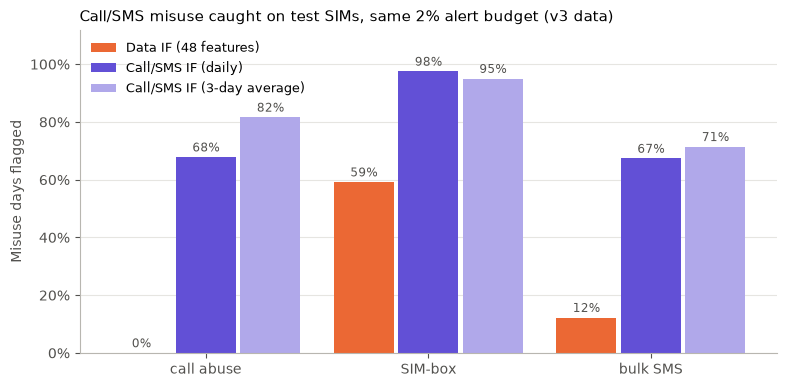

In [6]:
from matplotlib.ticker import PercentFormatter

COLORS = {"Data IF (48 features)": "#eb6834", "Call/SMS IF (daily)": "#6250d6", "Call/SMS IF (3-day average)": "#b0a8ea"}
NAMES = {"call_abuse": "call abuse", "sim_box": "SIM-box", "bulk_sms": "bulk SMS"}
x = np.arange(len(CALL_TYPES))
w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, name in enumerate(COLORS):
    vals = by_type[name].to_numpy()
    bars = ax.bar(x + (k - 1) * (w + 0.02), vals, w, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=2, fontsize=8.5, color="#52514e")
ax.set_xticks(x, [NAMES[c] for c in CALL_TYPES])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Misuse days flagged")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_title("Call/SMS misuse caught on test SIMs, same 2% alert budget (v3 data)", loc="left")
fig.savefig(REPORTS_DIR / "call_sms_detector_experiment.png", dpi=150, bbox_inches="tight")
plt.show()

### Where the false alarms come from
Normal days the call/SMS forest flags, split by the kind of normal SIM (heavy and international callers are legitimate in v3).

In [7]:
name = "Call/SMS IF (daily)"
fa = flags[name] & normal
Xt = Xc.iloc[test_idx]
sim_calls = Xc.loc[y == "normal"].groupby(df.loc[y == "normal", "sim_id"])["calls"].mean()
heavy = set(sim_calls[sim_calls >= sim_calls.quantile(0.95)].index)
intl = set(df.loc[(Xc["intl_call_share"].to_numpy() > 0) & (y == "normal"), "sim_id"])
kind = np.where(np.isin(sims_t, list(heavy)), "heavy caller (top 5% by calls)",
                np.where(np.isin(sims_t, list(intl)), "calls abroad sometimes", "other"))
pd.DataFrame({"normal test days": pd.Series(kind[normal]).value_counts(),
              "flagged": pd.Series(kind[fa]).value_counts()}).fillna(0).astype(int).assign(
    **{"flagged per 1,000": lambda t: (1000 * t["flagged"] / t["normal test days"]).round(1)})

,normal test days,flagged,"flagged per 1,000"
other,18320,180,9.8
calls abroad sometimes,1899,79,41.6
heavy caller (top 5% by calls),851,76,89.3


### Used together: data IF + call/SMS IF
If both run side by side, a day is flagged when either flags it.

In [8]:
both = flags["Data IF (48 features)"] | flags["Call/SMS IF (daily)"]
d = flags["Data IF (48 features)"]
pd.DataFrame({
    "Data IF alone": {"call/SMS misuse days caught": d[is_call].mean(), "data-misuse days flagged": d[is_data].mean(),
                      "false alarms per 1,000 normal days": 1000 * d[normal].mean()},
    "Data IF + call/SMS IF": {"call/SMS misuse days caught": both[is_call].mean(), "data-misuse days flagged": both[is_data].mean(),
                              "false alarms per 1,000 normal days": 1000 * both[normal].mean()},
}).round(3)

,Data IF alone,Data IF + call/SMS IF
call/SMS misuse days caught,0.301,0.816
data-misuse days flagged,0.268,0.272
"false alarms per 1,000 normal days",4.556,19.934


## 5. Findings and decision

**The dedicated call/SMS Isolation Forest is still clearly better than the data forest on call and SMS misuse**, now on misuse generated with realistic normal calling (test SIMs, same 2% alert budget):

| Detector | Call/SMS misuse days caught | First 2 days of an episode caught | False alarms per 1,000 normal days | PR-AUC (call/SMS misuse vs normal) |
|---|---|---|---|---|
| Data IF (48 features) | 30% | 6% | 4.6 | 0.20 |
| **Call/SMS IF (daily)** | **82%** | **88%** | 15.9 | 0.67 |
| Call/SMS IF (3-day average) | 86% | 59% | 14.7 | **0.76** |

**By type** (days caught, daily version): SIM-box 98%, call abuse 68%, bulk SMS 67%. Every call-abuse and bulk-SMS test SIM, and 8 of 9 SIM-box SIMs, is caught on at least one day. The data forest catches no call abuse at all (its data use does not change) and only part of SIM-box (59%, through its collapsing data and jump in sessions).

**What changed from the v2 experiment:**
- **False alarms are ten times higher** (15.9 vs 1.5 per 1,000 normal days). In v2 every normal SIM called the same way, so any change stood out. In v3 normal calling is realistic, and the false alarms come mostly from legitimate unusual callers: heavy callers (top 5% by calls) are flagged on 89 of every 1,000 normal days, SIMs that sometimes call abroad on 42, all other SIMs on 10.
- **Daily vs 3-day average is now a real trade-off.** The 3-day average ranks better overall (PR-AUC 0.76 vs 0.67) and catches slightly more misuse days, but it reacts later: it flags 59% of episodes' first two days against 88% for daily scoring.
- Normal calling now overlaps misuse more: the busiest 1% of normal days reach 13 calls, 26 call minutes and 11 SMS, so mild call abuse and small bulk-SMS bursts look like busy normal days.

**Used together with the data forest**, call/SMS misuse caught rises from 30% to 82%, data-misuse detection is unchanged (26.8% → 27.2%), and false alarms rise from 4.6 to 19.9 per 1,000 normal days.

**Caveats for the write-up:**
- The misuse patterns were designed by us in the generator, so these are results on *these* patterns, not real-world performance.
- The test set holds only 7-10 SIMs per call type, so per-type figures are rough.

**Decision:** keep the dedicated call/SMS Isolation Forest as the third model with its own alert type ("unusual calling/SMS"). It needs no labels, so it works from day one. Its setting is chosen in section 6: **3-day average at a 1% alert budget**, now used in notebook 01. Daily scoring at 2% reacted faster, but in the combined design most of its extra alerts were false.

The main remaining improvement is to reduce false alarms on legitimate heavy and international callers, for example by giving the forest more features relative to each SIM's own past (it has only 6 of 20 now).

## 6. Improving the call/SMS Isolation Forest

**The problem (section 4):** 14 of the 20 call/SMS features are absolute values (number of calls, minutes, SMS,
international share...). A legitimate heavy caller is unusual *compared with other SIMs* every day, so the forest flags
heavy callers about 9 times as often as other subscribers, and SIMs that sometimes call abroad about 4 times as often.

**Four feature sets are compared:**

| Set | Features | Idea |
|---|---|---|
| A. current | the 20 features from notebook 01 | starting point |
| B. + self-relative | A + 11 features comparing the day with the SIM's **own** past | heavy callers are normal *for themselves* |
| C. self-relative only | the 6 existing baseline ratios + the 11 new ones (no absolute counts or shares) | remove what makes heavy callers stand out |
| D. log counts + self-relative | B, with calls, minutes, SMS and call length log-scaled | keep absolute levels, but soften them |

Each is tried with `max_features` 1.0 and 0.5, and scored daily or as a 3-day average: 16 settings.

**Fair comparison:** settings are compared by 4-fold cross-validation **within the training SIMs** (fit on 3/4, score
the other 1/4, labels used only to grade). The test SIMs are used once at the end, to check the chosen settings.

**Measures:** PR-AUC (call/SMS misuse vs normal days, no threshold needed); at a 1% and a 2% alert budget, the share
of call/SMS misuse days caught, false alarms per 1,000 normal days and precision (share of alerts on call/SMS-misuse
or normal days that are real misuse); the share of episodes' first 2 days caught (speed); and false alarms on
legitimate heavy callers.

### 6.1 Self-relative call/SMS features

In [9]:
SHARES = ["long_call_share", "new_call_share", "intl_call_share", "offpeak_call_share", "repeat_call_share",
          "new_sms_share", "offpeak_sms_share"]

def self_relative(xc, data):
    """11 features comparing each day with the SIM's own earlier days only (needs rows sorted by sim_id, date)."""
    d = xc.copy()
    sim = data["sim_id"].to_numpy()
    d["sim_id"] = sim
    by = d.groupby("sim_id")
    out = pd.DataFrame(index=xc.index)
    for c in ["calls", "call_minutes", "sms"]:          # z-score against the previous 14 days
        w = by[c].shift(1).groupby(sim).rolling(14, min_periods=3)
        med = w.median().reset_index(level=0, drop=True)
        std = w.std().reset_index(level=0, drop=True)
        out[f"{c}_z"] = ((d[c] - med) / (std + 1)).fillna(0.0)
    lt = lambda c: (by[c].shift(1).groupby(sim).expanding(min_periods=3).median()
                    .reset_index(level=0, drop=True))
    out["mean_call_s_vs_longterm"] = (d["mean_call_s"] / (lt("mean_call_s") + 1)).fillna(1.0)
    for c in SHARES:                                     # difference from the SIM's usual share
        out[f"{c}_vs_usual"] = (d[c] - lt(c)).fillna(0.0)
    return out.astype(float)

assert (df[["sim_id", "date"]].sort_values(["sim_id", "date"]).index == df.index).all()
R = self_relative(Xc, df)

# Look-ahead test, as in notebook 01: removing March must not change any January-February value
cut = "2025-02-28"
early = df[df["date"] <= cut]
R_early = self_relative(build_call_features(EV[EV["date"] <= cut], early), early)
diff = (R_early - R.loc[early.index]).abs().to_numpy().max()
assert diff < 1e-9, diff
print(f"{R.shape[1]} new features, no look-ahead (largest difference without March: {diff:.0e})")
print(", ".join(R.columns))

COUNTS = ["calls", "call_minutes", "mean_call_s", "sms"]
BASE_RATIOS = [c for c in Xc.columns if c.endswith(("_vs_baseline", "_vs_longterm"))]
FEATURE_SETS = {
    "A. current": Xc,
    "B. + self-relative": Xc.join(R),
    "C. self-relative only": Xc[BASE_RATIOS].join(R),
    "D. log counts + self-relative": Xc.assign(**{c: np.log1p(Xc[c]) for c in COUNTS}).join(R),
}
pd.Series({k: v.shape[1] for k, v in FEATURE_SETS.items()}, name="features").to_frame()

11 new features, no look-ahead (largest difference without March: 0e+00)
calls_z, call_minutes_z, sms_z, mean_call_s_vs_longterm, long_call_share_vs_usual, new_call_share_vs_usual, intl_call_share_vs_usual, offpeak_call_share_vs_usual, repeat_call_share_vs_usual, new_sms_share_vs_usual, offpeak_sms_share_vs_usual


,features
A. current,20
B. + self-relative,31
C. self-relative only,17
D. log counts + self-relative,31


### 6.2 Compare the 16 settings (cross-validation on the training SIMs)

In [10]:
from sklearn.model_selection import GroupKFold

labels_all = pd.Series(y)
run_all = (labels_all != labels_all.groupby(groups).shift()).cumsum()
FIRST2 = np.isin(y, CALL_TYPES) & ((labels_all.groupby(run_all).cumcount() + 1).to_numpy() <= 2)
HEAVY = np.isin(groups, list(heavy))   # legitimate heavy callers (top 5% by calls on normal days, section 4)

def evaluate(score_fit, score_ev, ev_idx):
    lab = y[ev_idx]
    call, norm = np.isin(lab, CALL_TYPES), lab == "normal"
    keep = call | norm
    out = {"PR-AUC": average_precision_score(call[keep], score_ev[keep])}
    for b in (0.01, 0.02):
        f = score_ev >= np.quantile(score_fit, 1 - b)
        out[f"caught @{b:.0%}"] = f[call].mean()
        out[f"precision @{b:.0%}"] = f[call].sum() / max(1, (f & keep).sum())
        out[f"false alarms /1k @{b:.0%}"] = 1000 * f[norm].mean()
        if b == 0.01:
            out["first 2 days caught @1%"] = f[FIRST2[ev_idx]].mean()
            out["heavy-caller false alarms /1k @1%"] = 1000 * f[norm & HEAVY[ev_idx]].mean()
    return out

def fit_scores(F, mf, fit_i, ev_i):
    iso = IsolationForest(n_estimators=300, max_samples=4096, max_features=mf,
                          random_state=SEED, n_jobs=-1).fit(F.iloc[fit_i])
    return -iso.score_samples(F.iloc[fit_i]), -iso.score_samples(F.iloc[ev_i])

rows = []
t0 = time.time()
for fold, (fi, vi) in enumerate(GroupKFold(n_splits=4).split(train_idx, groups=groups[train_idx])):
    fit_i, val_i = train_idx[fi], train_idx[vi]
    for name, F in FEATURE_SETS.items():
        for mf in (1.0, 0.5):
            s_fit, s_val = fit_scores(F, mf, fit_i, val_i)
            for scoring in ("daily", "3-day avg"):
                a, b = (s_fit, s_val) if scoring == "daily" else (smooth(s_fit, fit_i), smooth(s_val, val_i))
                rows.append({"features": name, "max_features": mf, "scoring": scoring, "fold": fold,
                             **evaluate(a, b, val_i)})
cv_all = pd.DataFrame(rows)
KEYS = ["features", "max_features", "scoring"]
cv = cv_all.groupby(KEYS, sort=False).mean().drop(columns="fold")
cv.insert(1, "PR-AUC (std)", cv_all.groupby(KEYS, sort=False)["PR-AUC"].std())
print(f"{len(FEATURE_SETS) * 2 * 4} forests trained in {time.time() - t0:.0f}s; mean over 4 folds, sorted by PR-AUC")
cv.sort_values("PR-AUC", ascending=False).round(3)

32 forests trained in 88s; mean over 4 folds, sorted by PR-AUC


PR-AUC  PR-AUC (std)  \
features                      max_features scoring                           
A. current                    0.5          3-day avg   0.766         0.040   
                              1.0          3-day avg   0.749         0.041   
B. + self-relative            0.5          3-day avg   0.720         0.034   
A. current                    0.5          daily       0.713         0.056   
B. + self-relative            1.0          3-day avg   0.694         0.041   
D. log counts + self-relative 1.0          3-day avg   0.689         0.042   
A. current                    1.0          daily       0.679         0.060   
D. log counts + self-relative 0.5          3-day avg   0.667         0.040   
C. self-relative only         1.0          3-day avg   0.635         0.090   
                              0.5          3-day avg   0.628         0.083   
B. + self-relative            0.5          daily       0.575         0.069   
                              1.0          daily       0.541         0.072   
D. log counts + self-relative 1.0          daily       0.517         0.076   
                              0.5          daily       0.508         0.066   
C. self-relative only         0.5          daily       0.483         0.080   
                              1.0          daily       0.481         0.095   

                                                      caught @1%  \
features                      max_features scoring                 
A. current                    0.5          3-day avg       0.651   
                              1.0          3-day avg       0.635   
B. + self-relative            0.5          3-day avg       0.624   
A. current                    0.5          daily           0.622   
B. + self-relative            1.0          3-day avg       0.623   
D. log counts + self-relative 1.0          3-day avg       0.595   
A. current                    1.0          daily           0.593   
D. log counts + self-relative 0.5          3-day avg       0.587   
C. self-relative only         1.0          3-day avg       0.583   
                              0.5          3-day avg       0.576   
B. + self-relative            0.5          daily           0.509   
                              1.0          daily           0.478   
D. log counts + self-relative 1.0          daily           0.462   
                              0.5          daily           0.458   
C. self-relative only         0.5          daily           0.447   
                              1.0          daily           0.451   

                                                      precision @1%  \
features                      max_features scoring                    
A. current                    0.5          3-day avg          0.728   
                              1.0          3-day avg          0.713   
B. + self-relative            0.5          3-day avg          0.693   
A. current                    0.5          daily              0.697   
B. + self-relative            1.0          3-day avg          0.686   
D. log counts + self-relative 1.0          3-day avg          0.663   
A. current                    1.0          daily              0.671   
D. log counts + self-relative 0.5          3-day avg          0.665   
C. self-relative only         1.0          3-day avg          0.659   
                              0.5          3-day avg          0.639   
B. + self-relative            0.5          daily              0.575   
                              1.0          daily              0.545   
D. log counts + self-relative 1.0          daily              0.531   
                              0.5          daily              0.524   
C. self-relative only         0.5          daily              0.500   
                              1.0          daily              0.506   

                                                      false alarms /1k @1%  \
features                      max_features scoring                 

### 6.3 Check on the test SIMs
The current setting and the best daily and best 3-day-average settings from 6.2 (by PR-AUC), each trained on all
training SIMs and scored once on the test SIMs.

In [11]:
best_daily = cv.xs("daily", level="scoring")["PR-AUC"].idxmax()
best_avg = cv.xs("3-day avg", level="scoring")["PR-AUC"].idxmax()
CHECK = {"current (A, daily)": ("A. current", 1.0, "daily"),
         "current (A, 3-day avg)": ("A. current", 1.0, "3-day avg"),
         f"best daily ({best_daily[0][0]}, max_features {best_daily[1]})": (*best_daily, "daily"),
         f"best 3-day avg ({best_avg[0][0]}, max_features {best_avg[1]})": (*best_avg, "3-day avg")}

test_rows, test_scores = {}, {}
for label, (name, mf, scoring) in CHECK.items():
    s_tr, s_te = fit_scores(FEATURE_SETS[name], mf, train_idx, test_idx)
    if scoring == "3-day avg":
        s_tr, s_te = smooth(s_tr, train_idx), smooth(s_te, test_idx)
    test_rows[label] = evaluate(s_tr, s_te, test_idx)
    f = s_te >= np.quantile(s_tr, 0.99)
    for c in CALL_TYPES:
        test_rows[label][f"days caught @1%: {c}"] = f[yt == c].mean()
    test_rows[label]["data-misuse days flagged @1%"] = f[is_data].mean()
    test_scores[label] = (s_tr, s_te)
test_table = pd.DataFrame(test_rows)
test_table.round(3)

,"current (A, daily)","current (A, 3-day avg)","best daily (A, max_features 0.5)","best 3-day avg (A, max_features 0.5)"
PR-AUC,0.668,0.760,0.681,0.746
caught @1%,0.613,0.703,0.562,0.734
precision @1%,0.595,0.700,0.610,0.709
false alarms /1k @1%,5.078,3.654,4.366,3.654
first 2 days caught @1%,0.653,0.306,0.796,0.286
heavy-caller false alarms /1k @1%,38.778,51.704,44.653,61.105
caught @2%,0.816,0.859,0.848,0.879
precision @2%,0.384,0.415,0.397,0.428
false alarms /1k @2%,15.899,14.713,15.662,14.286
days caught @1%: call_abuse,0.460,0.609,0.506,0.563


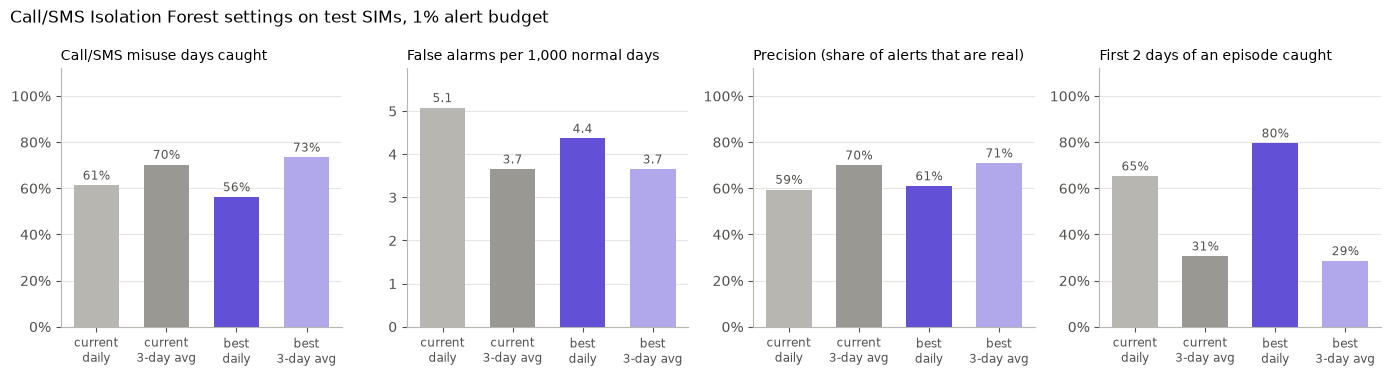

In [12]:
labels_ = list(CHECK)
short = ["current\ndaily", "current\n3-day avg", "best\ndaily", "best\n3-day avg"]
colors = ["#b8b6b0", "#9a9893", "#6250d6", "#b0a8ea"]
panels = [("caught @1%", "Call/SMS misuse days caught", True),
          ("false alarms /1k @1%", "False alarms per 1,000 normal days", False),
          ("precision @1%", "Precision (share of alerts that are real)", True),
          ("first 2 days caught @1%", "First 2 days of an episode caught", True)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (col, title, pct) in zip(axes, panels):
    vals = test_table.loc[col, labels_].to_numpy()
    bars = ax.bar(range(4), vals, 0.65, color=colors)
    ax.bar_label(bars, labels=[f"{v:.0%}" if pct else f"{v:.1f}" for v in vals], padding=2, fontsize=8.5, color="#52514e")
    ax.set_xticks(range(4), short, fontsize=8.5)
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
    if pct:
        ax.set_ylim(0, 1.12)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    else:
        ax.set_ylim(0, vals.max() * 1.18)
fig.suptitle("Call/SMS Isolation Forest settings on test SIMs, 1% alert budget", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "call_sms_if_improvement.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Findings: outcomes, advantages and disadvantages

**The main idea did not work.** Comparing each day with the SIM's own past (sets B, C, D) lowered the overall score in every combination. In cross-validation PR-AUC fell from 0.75-0.77 (set A, 3-day average) to 0.63-0.72, and false alarms rose. The two changes that did help are **3-day averaging** and, slightly, **`max_features=0.5`**, both on the current 20 features.

**Why the self-relative features backfired:** they did what they were meant to for heavy callers. With set C, heavy-caller false alarms fell from 28 to 9 per 1,000 of their normal days (cross-validation, 3-day average). But total false alarms still rose (3.0 → 3.6 per 1,000), so the other SIMs got worse. The likely reason is that most SIMs make only about 2 calls and 1 SMS a day. One call to a new number, or one long call, moves their "share vs usual" features a long way, so ordinary small changes look like big ones. With few calls, a SIM's "usual" is too noisy to compare against.

**Cross-validation results** (training SIMs, mean of 4 folds, 1% alert budget; the best and the current settings):

| Setting | PR-AUC | Caught | Precision | False alarms /1,000 | First 2 days caught | Heavy-caller false alarms /1,000 |
|---|---|---|---|---|---|---|
| A, max_features 0.5, 3-day avg | **0.77** | **65%** | **73%** | **2.9** | 34% | 35 |
| A, max_features 1.0, 3-day avg | 0.75 | 64% | 71% | 3.0 | 36% | 28 |
| A, max_features 0.5, daily | 0.71 | 62% | 70% | 3.1 | **72%** | 26 |
| A, max_features 1.0, daily (**current**) | 0.68 | 59% | 67% | 3.4 | 69% | 19 |
| B, + self-relative, 0.5, 3-day avg | 0.72 | 62% | 69% | 3.4 | 43% | 25 |
| C, self-relative only, 1.0, 3-day avg | 0.64 | 58% | 66% | 3.6 | 55% | **9** |

**Test SIMs** (checked once, 1% budget):

| Setting | Caught | Precision | False alarms /1,000 | First 2 days caught | Call abuse | SIM-box | Bulk SMS |
|---|---|---|---|---|---|---|---|
| Current (A, daily) | 61% | 59% | 5.1 | 65% | 46% | 80% | 43% |
| A, 3-day average | 70% | 70% | 3.7 | 31% | 61% | 88% | 43% |
| A, max_features 0.5, daily | 56% | 61% | 4.4 | **80%** | 51% | 61% | 55% |
| A, max_features 0.5, 3-day avg | **73%** | **71%** | 3.7 | 29% | 56% | 90% | 63% |

The test confirms the cross-validation ranking. The two 3-day settings are close (PR-AUC 0.75 vs 0.76): the difference between `max_features` 0.5 and 1.0 is smaller than the variation between folds (±0.04), so it is not a reliable gain.

**Advantages and disadvantages of each option:**

| Option | Advantages | Disadvantages |
|---|---|---|
| **Keep daily scoring** (current) | Fastest: catches 65-80% of episodes' first 2 days, so a SIM-box is flagged on day 1 | Lower precision (59-61% at 1%) and more false alarms; weaker on call abuse |
| **3-day average** | Best overall: about 70% caught at 70% precision, fewest false alarms (3.7 per 1,000), better on call abuse and SIM-box | Slow: only about 30% of episodes' first 2 days caught, so alerts arrive a day or two later. Heavy callers stay flagged longer, because averaging keeps a consistently busy SIM unusual |
| **`max_features=0.5`** | Small gain in cross-validation; matches the data forest's setting | Gain is within the noise; more false alarms on heavy callers (35 vs 28 per 1,000 in cross-validation) |
| **Self-relative features (B, C, D)** | Cut heavy-caller false alarms by up to two-thirds (set C) | Worse overall: more false alarms on ordinary low-usage SIMs, lower PR-AUC; 11 more features to compute and maintain |
| **1% budget instead of 2%** | About a quarter of the false alarms (3.7 vs 14.7 per 1,000 for the 3-day average) | Catches less: 70% vs 86% of call/SMS misuse days |

**Decision (applied in notebook 01):** keep the current 20 features, and score as a **3-day average at a 1% budget**, with `max_features` left at 1.0 (its gain from 0.5 is not reliable, and 1.0 gives fewer heavy-caller false alarms). This roughly doubles the alert precision of the current setting (59% → 70%) and cuts false alarms by a quarter. Since the Random Forest already catches known call misuse quickly, the call/SMS forest's job is the unknown kind, and there a day's delay matters less than a cleaner review queue.

**If speed matters more** (for example, to stop a SIM-box within hours), keep daily scoring at 1% instead: it catches 65% of first days, at 59% precision.

**Still open:** heavy callers remain the main source of false alarms (39-61 per 1,000 of their normal days on the test SIMs). Two ideas to try later: self-relative features only for SIMs with enough history (say, 5+ calls a day), or letting operators mark a SIM as a known heavy caller.